In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from river import datasets, drift
from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

# Load observations in their original order
records = []

for x, y in datasets.Elec2():
    records.append({**x, "target": int(y)})

df = pd.DataFrame(records)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isna().sum())
print("\nTarget distribution:")
print(df["target"].value_counts(normalize=True))

display(df.head())

Uncompressing into C:\Users\khush\river_data\Elec2
Shape: (45312, 9)

Columns: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer', 'target']

Missing values:
date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
target       0
dtype: int64

Target distribution:
target
0    0.575455
1    0.424545
Name: proportion, dtype: float64


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,target
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,1
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,0


In [2]:

FEATURES = [
    "day", "period",
    "nswprice", "nswdemand",
    "vicprice", "vicdemand",
    "transfer"
]

TRAIN_SIZE = 5000

train_df = df.iloc[:TRAIN_SIZE]
stream_df = df.iloc[TRAIN_SIZE:].copy()

X_train = train_df[FEATURES]
y_train = train_df["target"]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

model.fit(X_train, y_train)

print("Training accuracy:",
      accuracy_score(y_train, model.predict(X_train)))

print("Monitoring observations:", len(stream_df))

Training accuracy: 0.8198
Monitoring observations: 40312


In [3]:

def calculate_psi(reference, current, n_bins=10):
    edges = np.quantile(
        reference, np.linspace(0, 1, n_bins + 1)
    )

    edges[0] = -np.inf
    edges[-1] = np.inf
    edges = np.unique(edges)

    p = np.histogram(reference, bins=edges)[0].astype(float)
    q = np.histogram(current, bins=edges)[0].astype(float)

    eps = 1e-6
    p = np.maximum(p / p.sum(), eps)
    q = np.maximum(q / q.sum(), eps)

    p /= p.sum()
    q /= q.sum()

    return np.sum((q - p) * np.log(q / p))

In [4]:

BATCH_SIZE = 336
LABEL_DELAY_BATCHES = 2
MONITORED_FEATURE = "nswdemand"

reference = train_df[MONITORED_FEATURE].to_numpy()

adwin = drift.ADWIN(delta=0.002)

ph = drift.PageHinkley(
    min_instances=100,
    delta=0.005,
    threshold=30,
    mode="up"
)

pending_errors = []
results = []

for start in range(0, len(stream_df), BATCH_SIZE):

    batch = stream_df.iloc[start:start + BATCH_SIZE]
    batch_id = len(results) + 1

    X = batch[FEATURES]
    y = batch["target"].to_numpy()

    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    errors = (pred != y).astype(int)

    values = batch[MONITORED_FEATURE].to_numpy()

    ks_p = ks_2samp(reference, values).pvalue
    psi = calculate_psi(reference, values)

    adwin_alert = False
    for value in values:
        adwin.update(float(value))
        adwin_alert |= bool(adwin.drift_detected)

    # Simulate delayed availability of true labels
    pending_errors.append(errors)

    ph_alert = False

    if len(pending_errors) > LABEL_DELAY_BATCHES:
        available_errors = pending_errors.pop(0)

        for error in available_errors:
            ph.update(float(error))
            ph_alert |= bool(ph.drift_detected)

    results.append({
        "batch": batch_id,
        "accuracy": accuracy_score(y, pred),
        "roc_auc": (
            roc_auc_score(y, prob)
            if len(np.unique(y)) == 2 else np.nan
        ),
        "ks_pvalue": ks_p,
        "psi": psi,
        "ks_alert": ks_p < 0.05,
        "psi_alert": psi > 0.2,
        "adwin_alert": adwin_alert,
        "ph_alert": ph_alert
    })

results_df = pd.DataFrame(results)

display(results_df.head())
print("Batches monitored:", len(results_df))

,batch,accuracy,roc_auc,ks_pvalue,psi,ks_alert,psi_alert,adwin_alert,ph_alert
0,1,0.803571,0.893241,9.368095e-09,0.212547,True,True,True,False
1,2,0.747024,0.920478,2.207392e-01,0.071583,False,False,False,False
2,3,0.839286,0.935903,1.125339e-08,0.197827,True,False,False,False
3,4,0.848214,0.935905,1.402687e-19,1.435318,True,True,True,True
4,5,0.794643,0.922274,7.237987e-31,2.699917,True,True,False,False


Batches monitored: 120


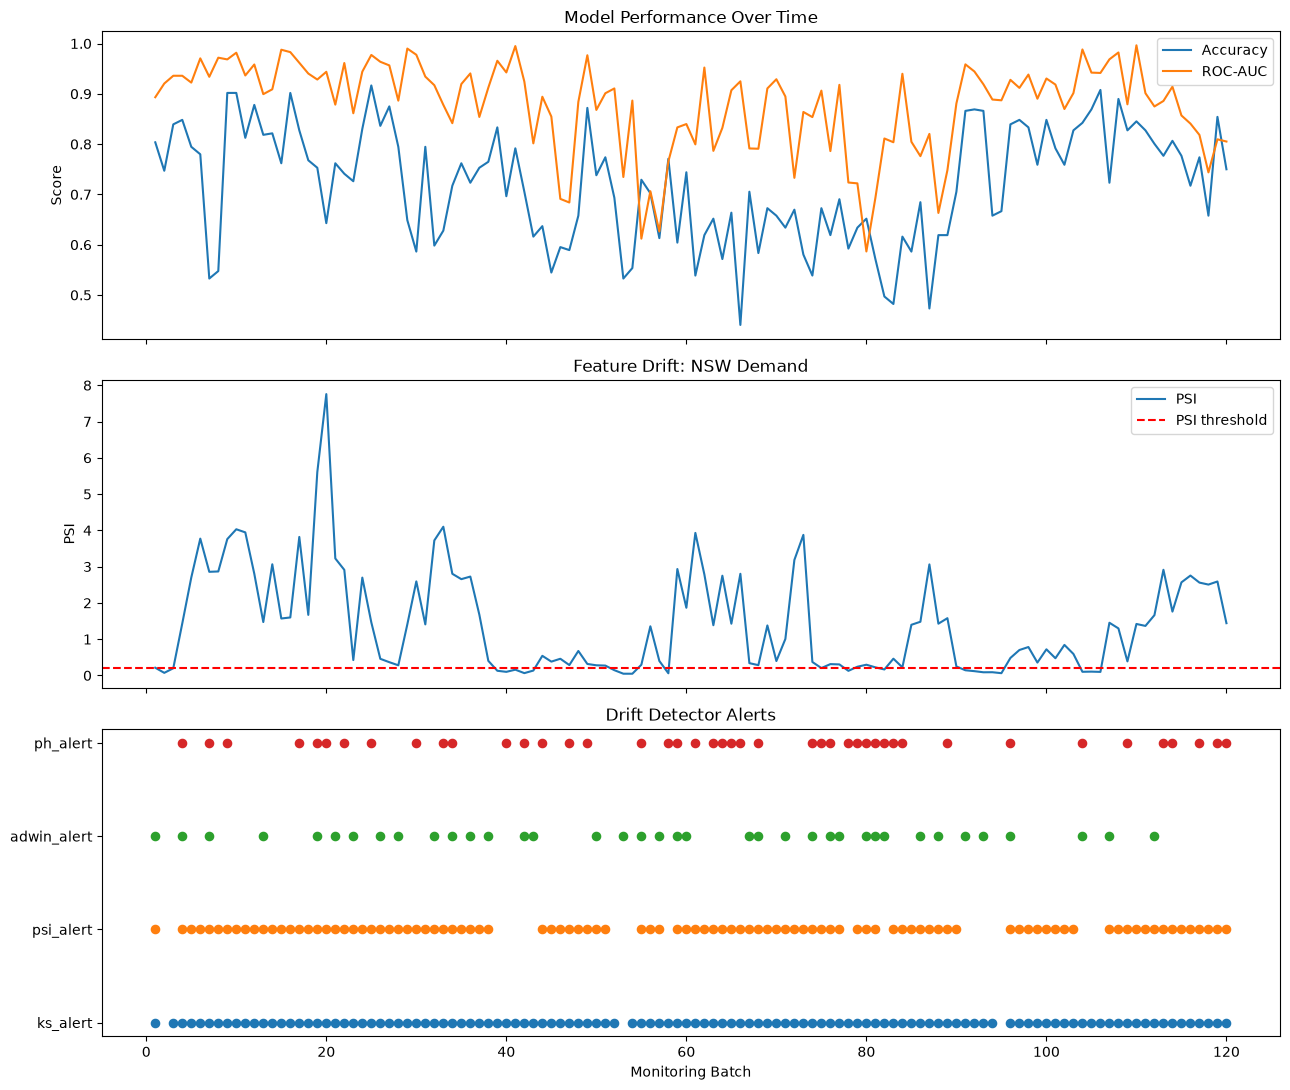

In [5]:

fig, axes = plt.subplots(
    3, 1, figsize=(13, 11), sharex=True
)

# Model performance
axes[0].plot(
    results_df["batch"],
    results_df["accuracy"],
    label="Accuracy"
)

axes[0].plot(
    results_df["batch"],
    results_df["roc_auc"],
    label="ROC-AUC"
)

axes[0].set_title("Model Performance Over Time")
axes[0].set_ylabel("Score")
axes[0].legend()

# Feature drift
axes[1].plot(
    results_df["batch"],
    results_df["psi"],
    label="PSI"
)

axes[1].axhline(
    0.2, linestyle="--",
    color="red", label="PSI threshold"
)

axes[1].set_title("Feature Drift: NSW Demand")
axes[1].set_ylabel("PSI")
axes[1].legend()

# Detector alerts
detectors = [
    "ks_alert",
    "psi_alert",
    "adwin_alert",
    "ph_alert"
]

for i, detector in enumerate(detectors):
    batches = results_df.loc[
        results_df[detector], "batch"
    ]

    axes[2].scatter(
        batches,
        [i] * len(batches),
        label=detector,
        s=35
    )

axes[2].set_yticks(range(4))
axes[2].set_yticklabels(detectors)
axes[2].set_xlabel("Monitoring Batch")
axes[2].set_title("Drift Detector Alerts")

plt.tight_layout()
plt.show()

In [6]:

# Require three consecutive alerting batches
PERSISTENCE = 3

for detector in ["ks", "psi", "adwin", "ph"]:
    alert_col = f"{detector}_alert"

    results_df[f"{detector}_persistent"] = (
        results_df[alert_col]
        .astype(int)
        .rolling(PERSISTENCE, min_periods=PERSISTENCE)
        .sum()
        .eq(PERSISTENCE)
    )

summary = pd.DataFrame({
    "Detector": ["KS", "PSI", "ADWIN", "Page-Hinkley"],
    "Raw Alert Batches": [
        results_df[f"{d}_alert"].sum()
        for d in ["ks", "psi", "adwin", "ph"]
    ],
    "Persistent Alert Batches": [
        results_df[f"{d}_persistent"].sum()
        for d in ["ks", "psi", "adwin", "ph"]
    ]
})

display(summary)

,Detector,Raw Alert Batches,Persistent Alert Batches
0,KS,117,110
1,PSI,99,82
2,ADWIN,38,1
3,Page-Hinkley,44,8


In [7]:

for detector in ["ks", "psi", "adwin", "ph"]:
    col = f"{detector}_persistent"

    current = results_df[col].astype(bool)

    # Notify only when the state switches False -> True
    results_df[f"{detector}_notification"] = (
        current & ~current.shift(1, fill_value=False)
    )

notification_summary = pd.DataFrame({
    "Detector": ["KS", "PSI", "ADWIN", "Page-Hinkley"],
    "Notification Episodes": [
        results_df[f"{d}_notification"].sum()
        for d in ["ks", "psi", "adwin", "ph"]
    ]
})

display(notification_summary)

,Detector,Notification Episodes
0,KS,3
1,PSI,8
2,ADWIN,1
3,Page-Hinkley,3


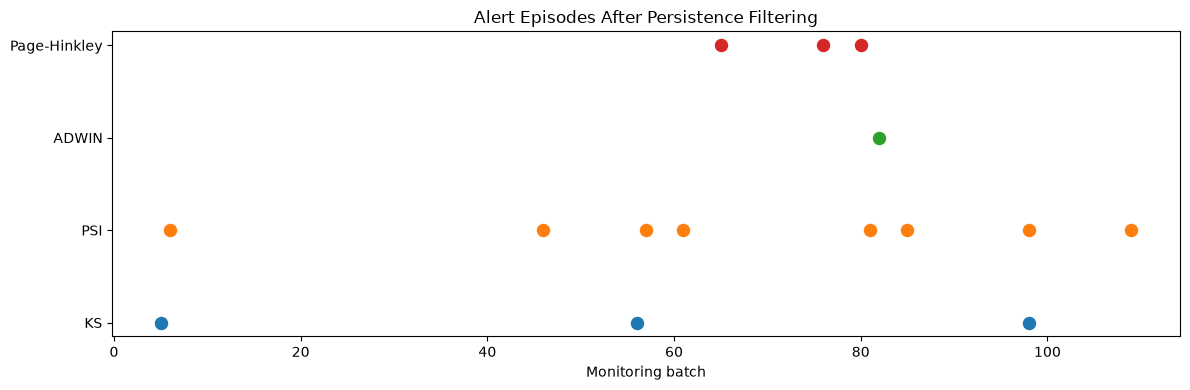

In [8]:

fig, ax = plt.subplots(figsize=(12, 4))

detectors = ["ks", "psi", "adwin", "ph"]

for i, detector in enumerate(detectors):
    notification_days = results_df.loc[
        results_df[f"{detector}_notification"],
        "batch"
    ]

    ax.scatter(
        notification_days,
        [i] * len(notification_days),
        s=75,
        label=detector
    )

ax.set_yticks(range(4))
ax.set_yticklabels(["KS", "PSI", "ADWIN", "Page-Hinkley"])
ax.set_xlabel("Monitoring batch")
ax.set_title("Alert Episodes After Persistence Filtering")

plt.tight_layout()
plt.show()

In [ ]:

# Batch-level distribution monitoring:
# Require 3 consecutive alerts and notify on transition.

for detector in ["ks", "psi"]:
    persistent = results_df[f"{detector}_persistent"]

    results_df[f"{detector}_notification_v2"] = (
        persistent &
        ~persistent.shift(1, fill_value=False)
    )

# Sequential change-point detectors:
# Each emitted detection represents an event.
# We retain each event instead of requiring persistence.

for detector in ["adwin", "ph"]:
    results_df[f"{detector}_notification_v2"] = (
        results_df[f"{detector}_alert"]
    )

summary_v2 = pd.DataFrame([
    {
        "Detector": d.upper(),
        "Notifications": int(
            results_df[f"{d}_notification_v2"].sum()
        )
    }
    for d in ["ks", "psi", "adwin", "ph"]
])

display(summary_v2)

,Detector,Notifications
0,KS,3
1,PSI,8
2,ADWIN,38
3,PH,44


In [10]:

# Compare model accuracy across PSI levels

results_df["psi_group"] = pd.cut(
    results_df["psi"],
    bins=[-np.inf, 0.2, 1.0, np.inf],
    labels=["Low", "Moderate", "High"]
)

summary = (
    results_df
    .groupby("psi_group", observed=True)
    .agg(
        batches=("accuracy", "size"),
        mean_accuracy=("accuracy", "mean"),
        median_accuracy=("accuracy", "median"),
        mean_auc=("roc_auc", "mean")
    )
)

display(summary.round(3))

# Spearman rank correlation
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    results_df["psi"],
    results_df["accuracy"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

,batches,mean_accuracy,median_accuracy,mean_auc
psi_group,,,,
Low,21,0.734,0.747,0.895
Moderate,38,0.711,0.716,0.848
High,61,0.722,0.744,0.891


Spearman correlation: -0.011
P-value: 0.9011


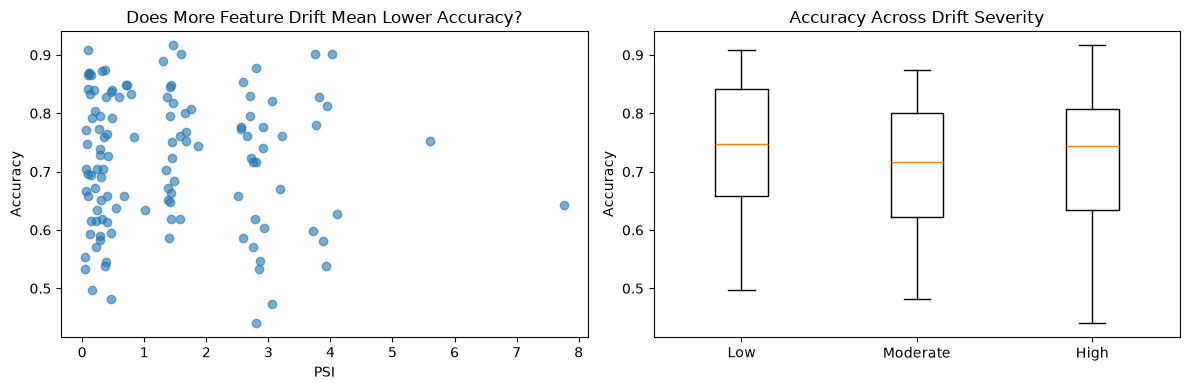

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    results_df["psi"],
    results_df["accuracy"],
    alpha=0.6
)

axes[0].set_xlabel("PSI")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Does More Feature Drift Mean Lower Accuracy?")

axes[1].boxplot(
    [
        results_df.loc[
            results_df["psi_group"] == group, "accuracy"
        ].dropna()
        for group in ["Low", "Moderate", "High"]
    ],
    tick_labels=["Low", "Moderate", "High"]
)

axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy Across Drift Severity")

plt.tight_layout()
plt.show()